# Industry Project: A Privacy-Safer Synthetic Customer Table for Developers (Production-Style)

> **Who is this notebook for?** Beginners who want to see how a company can give developers, testers or an outside vendor **realistic data without handing over real customers**.
> Every step is explained in plain English and almost every line of code has a comment.

---

### How this notebook is different from `01_synthetic_tabular_data.ipynb`

| `01_synthetic_tabular_data.ipynb` | This notebook |
|---|---|
| Overview of methods: Gaussian copula, SMOTE, CTGAN | One concrete use case: a **safe dev/test copy** of a customer table |
| Numeric columns, quality metrics shown one by one | Mixed types (dates, categories, missing values, PII), **business rules** that must hold |
| Generic evaluation | A **quality report with pass/fail gates**: fidelity, utility (train-synthetic-test-real), privacy (distance to closest record, exact copies, re-identification risk) |
| | Shows why "just remove the names" is **not** anonymization |

---

### The business problem

You work at a telecom / fintech company. The data team owns a `customers` table with personal data. Three groups want "realistic data":

1. **App developers** building a new customer portal need thousands of realistic rows for their test database.
2. **QA testers** need data that respects every business rule (otherwise their tests fail for the wrong reasons) **plus** edge cases.
3. An **outside analytics vendor** wants to prototype a churn model before the contract (and the data-processing agreement) is signed.

Privacy law (GDPR and similar) and the security team say: **no real customer data outside production**. Masking names is not enough (people can be re-identified from age + postcode + gender).

**Your job:** build a synthetic copy that is
- **useful**: similar distributions and relationships, a churn model trained on it works on real data;
- **valid**: every business rule holds, so the developers' code doesn't crash on impossible rows;
- **privacy-safer**: no synthetic row is a copy of, or suspiciously close to, a real customer;
- **documented**: a quality report with clear PASS/FAIL gates that the data-protection officer can sign off.

> ⚠️ "Privacy-safer", not "private": the simple generators here do **not** give a formal guarantee. For a formal guarantee you need **differential privacy** (see Resources). The checks in this notebook catch the most common leaks.

### Table of Contents
1. Setup and config
2. The real (sensitive) source table
3. Data contract: the business rules
4. Split the real data: training vs holdout
5. Generator 1: independent columns (baseline)
6. Generator 2: Gaussian copula (written with scipy)
7. A tempting "anonymization" that fails: real rows + noise
8. Enforce the business rules and add fake identifiers
9. Fidelity: do the columns and relationships look real?
10. Utility: train on synthetic, test on real (TSTR)
11. Privacy: distance to closest record, exact copies, re-identification risk
12. Edge cases for testers
13. The quality report with pass/fail gates
14. Package the dataset for developers
15. Automated tests
16. Summary, exercises and resources

---
## 1. Setup and config

> **Performance tip for shared machines:** gradient boosting in scikit-learn uses all CPU cores through OpenMP. On a busy shared server (CI runners, notebook servers, Kubernetes pods with CPU limits), many threads fighting for the same cores can make training **10-50× slower**. `threadpoolctl` lets you cap the threads; for small tables like ours one thread is plenty.

In [1]:
import json
import logging
import tempfile
import warnings
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats                                    # normal distribution, KS test
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("synthetic")
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1, user_api="openmp")   # see the performance tip above: avoid CPU over-subscription


@dataclass(frozen=True)
class Config:
    random_state: int = 42
    n_real: int = 8_000                    # size of the (simulated) production table
    holdout_share: float = 0.3             # real rows the generator never sees (for honest checks)
    n_synthetic: int = 5_000               # rows to deliver to developers
    snapshot_date: str = "2026-09-30"
    # Quality gates (agreed with the data-protection officer and the data consumers)
    max_ks_statistic: float = 0.10         # fidelity: per numeric column
    max_tvd: float = 0.10                  # fidelity: per categorical column (total variation distance)
    max_corr_diff: float = 0.10            # fidelity: mean absolute difference of correlations
    min_tstr_ratio: float = 0.90           # utility: synthetic-trained AUC >= 90% of real-trained AUC
    max_exact_copy_rate: float = 0.0       # privacy: no synthetic row identical to a real one
    max_closer_to_train_share: float = 0.60  # privacy: membership signal (0.5 = no signal)


CFG = Config()
SNAPSHOT = pd.Timestamp(CFG.snapshot_date)
print(CFG)

Config(random_state=42, n_real=8000, holdout_share=0.3, n_synthetic=5000, snapshot_date='2026-09-30', max_ks_statistic=0.1, max_tvd=0.1, max_corr_diff=0.1, min_tstr_ratio=0.9, max_exact_copy_rate=0.0, max_closer_to_train_share=0.6)


---
## 2. The real (sensitive) source table

In real life this is a production table that you would only read inside a secured environment:

```sql
-- Real-life version, run INSIDE the production network only (not run here)
SELECT * FROM crm.customers WHERE is_test_account = FALSE;
```

We simulate it with realistic structure: personal identifiers (name, email), quasi-identifiers (birth date, gender, postcode), skewed money columns, a column that is missing by design (`credit_limit` only exists for credit-card holders), dates that depend on each other, and a churn label driven by several columns.

In [2]:
FIRST = ["Anna", "Ben", "Chloe", "David", "Emma", "Farid", "Grace", "Hugo", "Ines", "Jonas", "Kofi", "Lena",
         "Mateo", "Nora", "Omar", "Priya", "Quinn", "Rosa", "Sven", "Tara", "Umar", "Vera", "Wei", "Yara"]
LAST = ["Smith", "Garcia", "Müller", "Kowalski", "Okafor", "Rossi", "Nguyen", "Silva", "Kim", "Dubois",
        "Jensen", "Novak", "Haddad", "Ivanova", "Brown", "Tanaka", "Moreau", "Schmidt", "Lopez", "Ahmed"]
REGIONS = {"North": ["101", "102", "103", "104"], "South": ["201", "202", "203"],
           "East": ["301", "302", "303", "304", "305"], "West": ["401", "402"], "Central": ["501", "502", "503"]}


def make_customer_table(n: int, seed: int) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    age = np.clip(rng.gamma(9, 4.8, n), 18, 92).astype(int)                     # skewed towards 30-50
    birth_date = SNAPSHOT - pd.to_timedelta(age * 365.25 + rng.integers(0, 365, n), unit="D")
    gender = rng.choice(["F", "M", "X"], n, p=[0.49, 0.49, 0.02])
    region = rng.choice(list(REGIONS), n, p=[0.25, 0.2, 0.3, 0.1, 0.15])
    postcode = np.array([rng.choice(REGIONS[r]) for r in region])
    income = np.round(rng.lognormal(10.4 + 0.012 * (age - 18) - 0.00015 * (age - 18) ** 2, 0.45, n), -2)
    plan_score = np.log(income) + rng.normal(0, 0.4, n)
    plan = np.where(plan_score > 11.2, "premium", np.where(plan_score > 10.5, "standard", "basic"))
    base_spend = pd.Series(plan).map({"basic": 22, "standard": 45, "premium": 80}).values
    monthly_spend = np.round(base_spend * rng.lognormal(0, 0.25, n), 2)
    monthly_spend = np.where(plan == "premium", np.maximum(monthly_spend, 50), monthly_spend)   # premium minimum fee
    num_products = np.clip(rng.poisson(1 + (plan == "premium") * 1.2 + (plan == "standard") * 0.5, n) + 1, 1, 8)
    has_credit_card = rng.random(n) < 1 / (1 + np.exp(-(np.log(income) - 10.3) * 2))
    credit_limit = np.where(has_credit_card, np.round(income * rng.uniform(0.1, 0.35, n), -2).clip(500, 50_000), np.nan)
    max_tenure = np.minimum((age - 18) * 12, 140)                               # can't be a customer before 18
    tenure_months = np.floor(rng.uniform(0, 1, n) ** 1.5 * max_tenure).astype(int) + 1
    signup_date = SNAPSHOT - pd.to_timedelta(tenure_months * 30.44, unit="D")
    support_calls_90d = rng.poisson(0.6 + 0.8 * (plan == "basic"), n)
    churn_logit = (-1.0 - 0.025 * tenure_months + 0.45 * support_calls_90d + 0.6 * (plan == "basic")
                   - 0.3 * num_products + 0.01 * (monthly_spend - 40) - 0.4 * has_credit_card)
    churned = (rng.random(n) < 1 / (1 + np.exp(-churn_logit))).astype(int)
    first, last = rng.choice(FIRST, n), rng.choice(LAST, n)
    return pd.DataFrame({
        "customer_id": [f"C{1_000_000 + i}" for i in range(n)],
        "full_name": [f"{f} {l}" for f, l in zip(first, last)],
        "email": [f"{f.lower()}.{l.lower()}{rng.integers(1, 999)}@example.com" for f, l in zip(first, last)],
        "birth_date": birth_date.normalize(), "gender": gender, "region": region, "postcode": postcode,
        "annual_income": income, "plan": plan, "monthly_spend": monthly_spend, "num_products": num_products,
        "has_credit_card": has_credit_card, "credit_limit": credit_limit, "signup_date": signup_date.normalize(),
        "tenure_months": tenure_months, "support_calls_90d": support_calls_90d, "churned": churned,
    })


real = make_customer_table(CFG.n_real, CFG.random_state)
print(f"{len(real):,} real customers | churn rate {real['churned'].mean():.1%}")
real.head()

8,000 real customers | churn rate 12.3%


,customer_id,full_name,email,birth_date,gender,region,postcode,annual_income,plan,monthly_spend,num_products,has_credit_card,credit_limit,signup_date,tenure_months,support_calls_90d,churned
0,C1000000,Yara Ahmed,yara.ahmed710@example.com,1980-08-16,M,East,305,61900.0,premium,73.07,3,True,8600.0,2023-06-30,39,1,0
1,C1000001,Quinn Jensen,quinn.jensen167@example.com,1973-09-24,M,South,203,46400.0,standard,61.77,3,False,NaN,2016-01-29,128,0,0
2,C1000002,Rosa Jensen,rosa.jensen482@example.com,2007-04-14,F,East,302,74400.0,standard,44.19,3,True,11000.0,2026-08-30,1,0,0
3,C1000003,Anna Kim,anna.kim859@example.com,1983-06-26,F,West,401,54500.0,standard,37.04,3,True,16800.0,2022-11-29,46,0,0
4,C1000004,Priya Kowalski,priya.kowalski521@example.com,1984-12-28,M,North,102,21400.0,basic,31.41,1,False,NaN,2024-12-29,21,2,0


### Classify every column first

Before generating anything, a privacy-aware team labels each column. This decides how it is treated:

| Type | Columns | Treatment |
|---|---|---|
| **Direct identifiers** | `customer_id`, `full_name`, `email` | **Never** learned from. Replaced by obviously fake values |
| **Quasi-identifiers** | `birth_date`, `gender`, `postcode`, `region` | Learned, but re-identification risk is checked |
| **Sensitive attributes** | `annual_income`, `credit_limit`, `churned` | Learned; must not be traceable to a person |
| **Other attributes** | plan, spend, products, tenure, calls, dates | Learned |

In [3]:
DIRECT_IDENTIFIERS = ["customer_id", "full_name", "email"]
QUASI_IDENTIFIERS = ["age", "gender", "postcode"]          # age is derived from birth_date below
CATEGORICAL = ["gender", "region", "postcode", "plan", "has_credit_card"]
NUMERIC = ["age", "annual_income", "monthly_spend", "num_products", "credit_limit", "tenure_months",
           "support_calls_90d"]
TARGET = "churned"


def to_model_table(df: pd.DataFrame) -> pd.DataFrame:
    """Drop direct identifiers and turn dates into numbers that generators can learn."""
    out = df.drop(columns=DIRECT_IDENTIFIERS, errors="ignore").copy()
    out["age"] = ((SNAPSHOT - pd.to_datetime(out.pop("birth_date"))).dt.days // 365.25).astype(int)
    out = out.drop(columns=["signup_date"])                 # fully determined by tenure_months (rebuilt later)
    out["has_credit_card"] = out["has_credit_card"].astype(str)
    return out[CATEGORICAL + NUMERIC + [TARGET]]


real_model = to_model_table(real)
real_model.head()

,gender,region,postcode,plan,has_credit_card,age,annual_income,monthly_spend,num_products,credit_limit,tenure_months,support_calls_90d,churned
0,M,East,305,premium,True,46,61900.0,73.07,3,8600.0,39,1,0
1,M,South,203,standard,False,53,46400.0,61.77,3,NaN,128,0,0
2,F,East,302,standard,True,19,74400.0,44.19,3,11000.0,1,0,0
3,F,West,401,standard,True,43,54500.0,37.04,3,16800.0,46,0,0
4,M,North,102,basic,False,41,21400.0,31.41,1,NaN,21,2,0


---
## 3. Data contract: the business rules

The developers' application assumes these rules. A synthetic row that breaks one would trigger errors that never happen in production, and testers would waste days on fake bugs. We write the rules **once** as small functions and use them to check every dataset (real, synthetic, edge cases).

In [4]:
RULES = {
    "age between 18 and 100": lambda d: d["age"].between(18, 100),
    "customer for at most (age - 18) years": lambda d: d["tenure_months"] <= (d["age"] - 18) * 12 + 12,
    "tenure at least 1 month": lambda d: d["tenure_months"] >= 1,
    "premium plan pays at least $50": lambda d: (d["plan"] != "premium") | (d["monthly_spend"] >= 50),
    "credit limit only with a card": lambda d: (d["has_credit_card"] == "True") == d["credit_limit"].notna(),
    "credit limit between 500 and 50,000": lambda d: d["credit_limit"].isna() | d["credit_limit"].between(500, 50_000),
    "postcode belongs to region": lambda d: [p in REGIONS.get(r, []) for r, p in zip(d["region"], d["postcode"])],
    "counts are non-negative integers": lambda d: (d[["num_products", "support_calls_90d"]] >= 0).all(axis=1)
                                                  & (d[["num_products", "support_calls_90d"]] % 1 == 0).all(axis=1),
    "num_products between 1 and 8": lambda d: d["num_products"].between(1, 8),
}


def rule_violations(df: pd.DataFrame) -> pd.Series:
    """Share of rows that break each rule (0.0 = rule always holds)."""
    return pd.Series({name: 1 - np.mean(np.asarray(rule(df), dtype=bool)) for name, rule in RULES.items()})


print("Real data (should be all zero):")
print(rule_violations(real_model).round(4).to_string())

Real data (should be all zero):
age between 18 and 100                   0.0
customer for at most (age - 18) years    0.0
tenure at least 1 month                  0.0
premium plan pays at least $50           0.0
credit limit only with a card            0.0
credit limit between 500 and 50,000      0.0
postcode belongs to region               0.0
counts are non-negative integers         0.0
num_products between 1 and 8             0.0


---
## 4. Split the real data: training vs holdout

The generators learn only from **70%** of the real rows. The other **30%** (the *holdout*) is never shown to them. We need it for two honest checks:
- **utility:** a model trained on synthetic data is tested on real holdout rows;
- **privacy:** a good generator should produce rows that are no closer to its training customers than to holdout customers it never saw. If synthetic rows sit much closer to training rows, the generator has **memorised** real people.

In [5]:
real_train, real_holdout = train_test_split(real_model, test_size=CFG.holdout_share,
                                            stratify=real_model[TARGET], random_state=CFG.random_state)
real_train, real_holdout = real_train.reset_index(drop=True), real_holdout.reset_index(drop=True)
print(f"generator training rows: {len(real_train):,} | holdout rows: {len(real_holdout):,}")

generator training rows: 5,600 | holdout rows: 2,400


---
## 5. Generator 1: independent columns (baseline)

The simplest generator: sample every column **independently** from its own real distribution. Each column on its own looks perfect, but all **relationships** are destroyed (income no longer drives the plan, tenure no longer depends on age...). It is our baseline: everything else must beat it.

In [6]:
class IndependentSampler:
    """Samples each column independently from its empirical distribution."""

    def fit(self, df: pd.DataFrame):
        self.columns = {c: df[c].values for c in df.columns}
        return self

    def sample(self, n: int, seed: int = 0) -> pd.DataFrame:
        rng = np.random.default_rng(seed)
        return pd.DataFrame({c: rng.choice(v, n) for c, v in self.columns.items()})


synth_independent = IndependentSampler().fit(real_train).sample(CFG.n_synthetic, seed=1)
print("Rule violations of the independent sampler:")
print(rule_violations(synth_independent).round(3).to_string())

Rule violations of the independent sampler:
age between 18 and 100                   0.000
customer for at most (age - 18) years    0.044
tenure at least 1 month                  0.000
premium plan pays at least $50           0.107
credit limit only with a card            0.470
credit limit between 500 and 50,000      0.000
postcode belongs to region               0.773
counts are non-negative integers         0.000
num_products between 1 and 8             0.000


Even this "baseline" breaks several business rules (for example, credit limits without a card, or teenagers with 20 years of tenure), because the columns no longer know about each other.

---
## 6. Generator 2: Gaussian copula (written with scipy)

A **Gaussian copula** keeps each column's own distribution **and** the correlations between columns. It is the default model in tools like SDV and a strong, fast, explainable choice. The idea in four steps:

1. **To ranks:** for every column, replace each value by its rank (0 to 1). Categories are first turned into numbers ordered by frequency.
2. **To normal:** turn ranks into standard-normal "z-scores" with the inverse normal CDF (`stats.norm.ppf`). Now every column looks like a bell curve.
3. **Learn correlations** between these z-scores (one correlation matrix).
4. **Sample:** draw new z-scores from a multivariate normal with that correlation matrix, then go back: z → rank → value, using each column's real **quantiles**.

Missing values (`credit_limit` for people without a card) get a 0 placeholder before fitting; the rules in Section 8 put the `NaN` back.

In [7]:
class GaussianCopulaSynthesizer:
    """Gaussian copula for mixed numeric / categorical tables, in readable numpy + scipy."""

    def __init__(self, categorical: list[str], integer: list[str]):
        self.categorical, self.integer = categorical, integer

    def _encode(self, df: pd.DataFrame) -> pd.DataFrame:
        out = df.copy()
        for c in self.categorical:                         # categories -> codes, most frequent first
            out[c] = out[c].map(self.cat_codes[c])
        return out.fillna(0.0).astype(float)               # placeholder for missing values

    def fit(self, df: pd.DataFrame):
        self.columns = list(df.columns)
        self.cat_codes = {c: {v: i for i, v in enumerate(df[c].value_counts().index)} for c in self.categorical}
        encoded = self._encode(df)
        self.sorted_values = {c: np.sort(encoded[c].values) for c in self.columns}   # for the inverse CDF
        ranks = encoded.rank(method="average") / (len(encoded) + 1)              # step 1: values -> (0, 1)
        z = stats.norm.ppf(ranks)                                                # step 2: -> standard normal
        self.corr = np.corrcoef(z, rowvar=False)                                 # step 3: correlations
        return self

    def sample(self, n: int, seed: int = 0) -> pd.DataFrame:
        rng = np.random.default_rng(seed)
        z = rng.multivariate_normal(np.zeros(len(self.columns)), self.corr, size=n)   # step 4: new z-scores
        u = stats.norm.cdf(z)                                                         # z -> (0, 1)
        out = {}
        for j, c in enumerate(self.columns):
            discrete = c in self.categorical or c in self.integer
            # inverse CDF: the u-th quantile of the real column ("linear" smooths continuous columns)
            out[c] = np.quantile(self.sorted_values[c], u[:, j], method="inverted_cdf" if discrete else "linear")
        out = pd.DataFrame(out)
        for c in self.categorical:                                                    # codes -> categories
            out[c] = out[c].round().astype(int).map({i: v for v, i in self.cat_codes[c].items()})
        for c in self.integer:
            out[c] = out[c].round().astype(int)
        return out[self.columns]


INTEGER = ["age", "num_products", "tenure_months", "support_calls_90d", TARGET]
copula = GaussianCopulaSynthesizer(categorical=CATEGORICAL, integer=INTEGER).fit(real_train)
synth_copula_raw = copula.sample(CFG.n_synthetic, seed=2)
print("Rule violations of the Gaussian copula BEFORE rule enforcement:")
print(rule_violations(synth_copula_raw).round(3).to_string())

Rule violations of the Gaussian copula BEFORE rule enforcement:
age between 18 and 100                   0.000
customer for at most (age - 18) years    0.028
tenure at least 1 month                  0.000
premium plan pays at least $50           0.014
credit limit only with a card            0.384
credit limit between 500 and 50,000      0.380
postcode belongs to region               0.744
counts are non-negative integers         0.000
num_products between 1 and 8             0.000


Better than the independent sampler on rules that come from correlations (age vs tenure, premium vs spend), but far from perfect: a copula captures **smooth** relationships, not **hard** rules like "a postcode belongs to exactly one region" or "no card means no limit". Two standard fixes, used together in practice:

1. **Model hierarchical columns conditionally** (next cell): the copula only learns `region`; the `postcode` is then drawn from the real distribution of postcodes **within** that region. The same trick works for country → city, product category → product, etc.
2. An explicit **rule-enforcement** step for the rest (Section 8).

> **Deep-learning generators** (CTGAN, TVAE; see `01_synthetic_tabular_data.ipynb`) can learn more complex patterns but need much more data and tuning, and they still break hard rules. Industry teams usually start with a copula, measure, and only move to deep models if the quality report says it's needed.

---
## 7. A tempting "anonymization" that fails: real rows + noise

Someone suggests a shortcut: *"just take the real rows, remove names and emails, and add 1% random noise to the numbers"*. It looks great on every quality metric, because it **is** the real data. We include it to show that the privacy checks in Section 11 catch it.

In [8]:
class CopulaWithHierarchy:
    # Gaussian copula for everything except postcode; postcode is sampled given the region
    def fit(self, df: pd.DataFrame):
        self.columns = list(df.columns)
        self.copula = GaussianCopulaSynthesizer(categorical=[c for c in CATEGORICAL if c != "postcode"],
                                                integer=INTEGER).fit(df.drop(columns="postcode"))
        # P(postcode | region) from the real training data, e.g. North -> {101: 0.26, 102: 0.24, ...}
        self.postcodes = {r: g.value_counts(normalize=True) for r, g in df.groupby("region")["postcode"]}
        return self

    def sample(self, n: int, seed: int = 0) -> pd.DataFrame:
        rng = np.random.default_rng(seed)
        out = self.copula.sample(n, seed)
        out["postcode"] = [rng.choice(self.postcodes[r].index, p=self.postcodes[r].values) for r in out["region"]]
        return out[self.columns]


copula_gen = CopulaWithHierarchy().fit(real_train)
print("Rule violations of the hierarchical copula BEFORE rule enforcement:")
print(rule_violations(copula_gen.sample(CFG.n_synthetic, seed=2)).round(3).to_string())

Rule violations of the hierarchical copula BEFORE rule enforcement:


age between 18 and 100                   0.000
customer for at most (age - 18) years    0.033
tenure at least 1 month                  0.000
premium plan pays at least $50           0.019
credit limit only with a card            0.369
credit limit between 500 and 50,000      0.370
postcode belongs to region               0.000
counts are non-negative integers         0.000
num_products between 1 and 8             0.000


In [9]:
def noisy_copy(df: pd.DataFrame, n: int, noise: float = 0.01, seed: int = 3) -> pd.DataFrame:
    """The WRONG way: resample real rows and jitter numbers by ~1%."""
    rng = np.random.default_rng(seed)
    out = df.sample(n, replace=True, random_state=seed).reset_index(drop=True)
    for c in ["annual_income", "monthly_spend", "credit_limit"]:
        out[c] = (out[c] * (1 + rng.normal(0, noise, n))).round(2)
    return out


synth_noisy = noisy_copy(real_train, CFG.n_synthetic)

---
## 8. Enforce the business rules and add fake identifiers

Two common strategies for rows that break a rule:
- **Repair** the row when there is an obvious fix (e.g. "no card → set credit limit to empty", "premium with $45 spend → raise to the $50 minimum").
- **Reject** the row and sample a new one when no sensible fix exists (e.g. a postcode from the wrong region).

Then we rebuild the columns we removed, **consistently with the rules**: dates from age and tenure, and obviously fake names, emails and ids. Fake identifiers use a reserved test domain (`example.com`, which is reserved for documentation) and a distinct id prefix (`SYN-`), so nobody can confuse a synthetic row with a real customer.

In [10]:
def repair(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    no_card = df["has_credit_card"] != "True"
    df.loc[no_card, "credit_limit"] = np.nan                                  # no card -> no limit
    df.loc[~no_card, "credit_limit"] = (df.loc[~no_card, "credit_limit"].clip(500, 50_000) / 100).round() * 100
    premium = df["plan"] == "premium"
    df.loc[premium, "monthly_spend"] = df.loc[premium, "monthly_spend"].clip(lower=50)   # premium minimum fee
    df["age"] = df["age"].clip(18, 100)
    df["annual_income"] = df["annual_income"].round(-2)                     # same format as production
    df["monthly_spend"] = df["monthly_spend"].round(2)
    df["num_products"] = df["num_products"].clip(1, 8)
    df["tenure_months"] = np.minimum(df["tenure_months"].clip(lower=1), (df["age"] - 18) * 12 + 12)
    return df


def enforce_rules(generator, n: int, seed: int, max_rounds: int = 10) -> tuple[pd.DataFrame, dict]:
    """Repair what can be repaired, reject the rest, and top up with fresh samples until we have n valid rows."""
    kept, stats_ = [], {"sampled": 0, "rejected": 0}
    for round_ in range(max_rounds):
        batch = repair(generator.sample(int(n * 1.3), seed=seed + round_))
        valid = np.logical_and.reduce([np.asarray(rule(batch), dtype=bool) for rule in RULES.values()])
        stats_["sampled"] += len(batch); stats_["rejected"] += int((~valid).sum())
        kept.append(batch[valid])
        if sum(map(len, kept)) >= n:
            break
    return pd.concat(kept).head(n).reset_index(drop=True), stats_


def add_fake_identifiers(df: pd.DataFrame, seed: int = 0) -> pd.DataFrame:
    """Rebuild id / name / email / dates. Fake names are combinations NOT taken from the real table's rows."""
    rng = np.random.default_rng(seed)
    out = df.copy()
    out.insert(0, "customer_id", [f"SYN-{i:06d}" for i in range(len(out))])
    first, last = rng.choice(FIRST, len(out)), rng.choice(LAST, len(out))
    out.insert(1, "full_name", [f"{f} {l}" for f, l in zip(first, last)])
    out.insert(2, "email", [f"test.user{i}@example.com" for i in range(len(out))])
    out["birth_date"] = (SNAPSHOT - pd.to_timedelta(out["age"] * 365.25 + rng.integers(0, 365, len(out)), unit="D")).dt.normalize()
    out["signup_date"] = (SNAPSHOT - pd.to_timedelta(out["tenure_months"] * 30.44, unit="D")).dt.normalize()
    return out


synth_copula, enforcement_stats = enforce_rules(copula_gen, CFG.n_synthetic, seed=10)
log.info("Copula: sampled %d rows, rejected %d (%.1f%%) after repair", enforcement_stats["sampled"],
         enforcement_stats["rejected"], 100 * enforcement_stats["rejected"] / enforcement_stats["sampled"])
synth_independent_fixed, _ = enforce_rules(IndependentSampler().fit(real_train), CFG.n_synthetic, seed=20)
print("Violations after enforcement (copula):", rule_violations(synth_copula).max())
add_fake_identifiers(synth_copula).head()

2026-10-21 17:31:00,919 | INFO | Copula: sampled 6500 rows, rejected 0 (0.0%) after repair


Violations after enforcement (copula): 0.0


,customer_id,full_name,email,gender,region,postcode,plan,has_credit_card,age,annual_income,monthly_spend,num_products,credit_limit,tenure_months,support_calls_90d,churned,birth_date,signup_date
0,SYN-000000,Umar Lopez,test.user0@example.com,M,North,101,standard,True,44,55100.0,80.61,2,12400.0,4,0,0,1982-01-25,2026-05-31
1,SYN-000001,Priya Brown,test.user1@example.com,F,Central,502,standard,True,55,36500.0,68.30,4,500.0,40,1,1,1970-11-11,2023-05-31
2,SYN-000002,Mateo Brown,test.user2@example.com,M,South,202,standard,True,18,44600.0,39.33,1,7600.0,12,1,0,2008-04-02,2025-09-29
3,SYN-000003,Grace Müller,test.user3@example.com,M,North,104,basic,False,59,45300.0,23.30,2,NaN,79,1,0,1967-01-21,2020-02-29
4,SYN-000004,Hugo Silva,test.user4@example.com,M,North,103,standard,False,22,28700.0,49.38,2,NaN,60,1,1,2004-01-03,2021-09-29


---
## 9. Fidelity: do the columns and relationships look real?

Three levels of checks, from simple to strict:
1. **Each numeric column:** the **Kolmogorov-Smirnov (KS) statistic** = the largest gap between the real and synthetic cumulative distributions (0 = identical, 1 = completely different).
2. **Each categorical column:** the **total variation distance (TVD)** = half the sum of absolute differences between category shares (0 = identical shares).
3. **Relationships:** the mean absolute difference between the real and synthetic **correlation matrices** (Spearman correlations on numeric + encoded categorical columns).

We compare against the real **holdout**: real-vs-real differences show what "perfect" looks like with this sample size.

In [11]:
def encode_for_corr(df: pd.DataFrame) -> pd.DataFrame:
    out = df[NUMERIC + [TARGET]].copy()
    out["credit_limit"] = out["credit_limit"].fillna(0)
    for c in ["plan", "has_credit_card", "gender"]:
        out[c] = df[c].astype("category").cat.codes
    out["plan"] = df["plan"].map({"basic": 0, "standard": 1, "premium": 2})         # ordered
    return out


def fidelity(reference: pd.DataFrame, candidate: pd.DataFrame) -> dict:
    ks = {c: stats.ks_2samp(reference[c].fillna(0), candidate[c].fillna(0)).statistic for c in NUMERIC}
    tvd = {c: 0.5 * (reference[c].value_counts(normalize=True)
                     .subtract(candidate[c].value_counts(normalize=True), fill_value=0).abs().sum())
           for c in CATEGORICAL + [TARGET]}
    corr_diff = np.abs(encode_for_corr(reference).corr("spearman") - encode_for_corr(candidate).corr("spearman"))
    n = len(corr_diff)
    return {"ks": ks, "tvd": tvd, "corr_diff": float(corr_diff.values[np.triu_indices(n, 1)].mean())}


DATASETS = {"real holdout (reference)": real_holdout, "independent + rules": synth_independent_fixed,
            "Gaussian copula + rules": synth_copula, "noisy copy (bad idea)": synth_noisy}
fid = {name: fidelity(real_train, d) for name, d in DATASETS.items()}
fidelity_table = pd.DataFrame({name: {"max KS (numeric)": max(f["ks"].values()),
                                      "max TVD (categorical)": max(f["tvd"].values()),
                                      "mean |corr diff|": f["corr_diff"]} for name, f in fid.items()}).T
fidelity_table.round(3)

,max KS (numeric),max TVD (categorical),mean |corr diff|
real holdout (reference),0.025,0.043,0.021
independent + rules,0.112,0.133,0.151
Gaussian copula + rules,0.088,0.020,0.035
noisy copy (bad idea),0.016,0.022,0.009


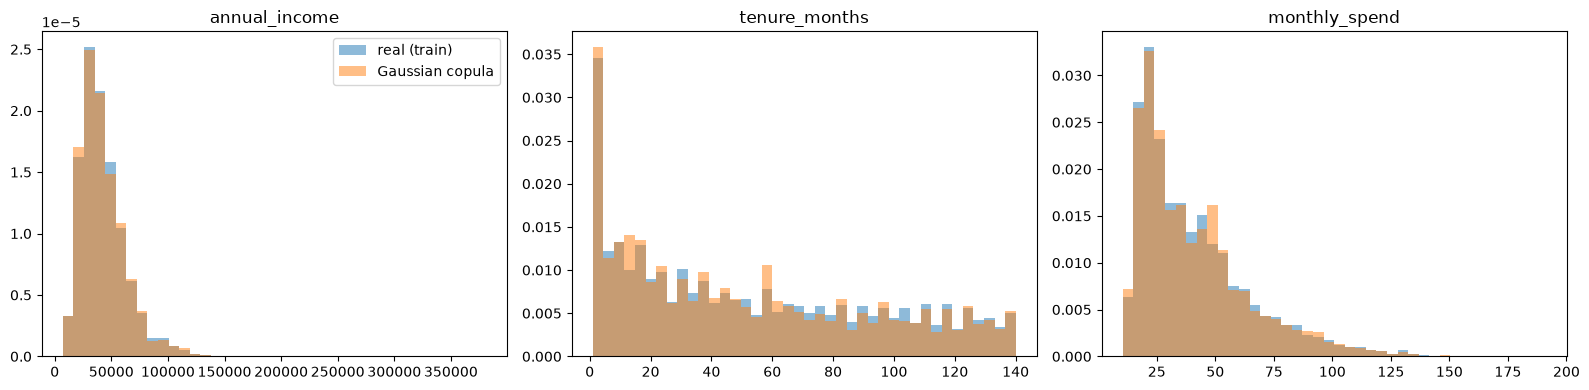

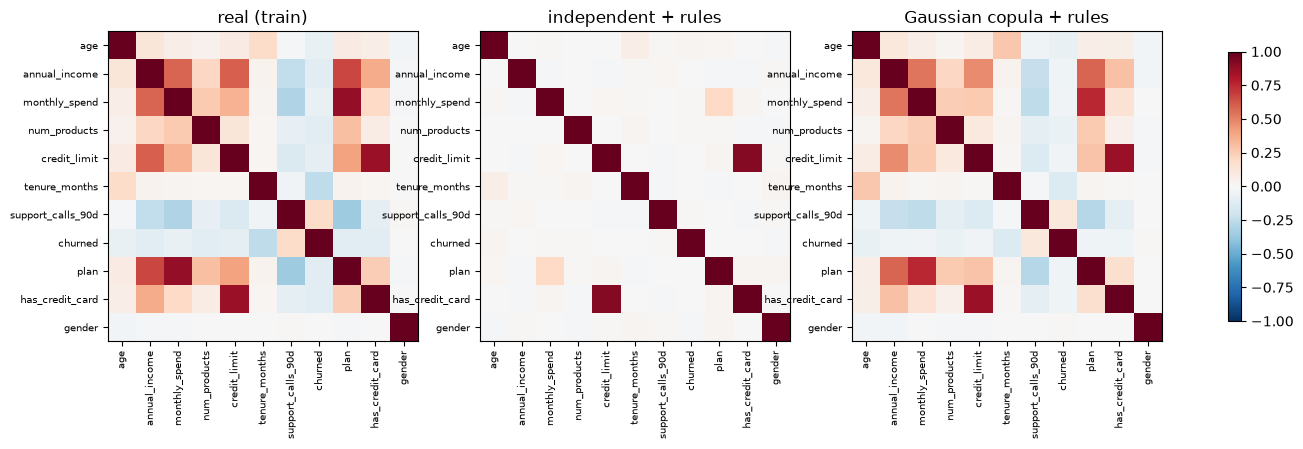

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["annual_income", "tenure_months", "monthly_spend"]):
    bins = np.histogram_bin_edges(real_train[col], bins=40)
    ax.hist(real_train[col], bins=bins, density=True, alpha=0.5, label="real (train)")
    ax.hist(synth_copula[col], bins=bins, density=True, alpha=0.5, label="Gaussian copula")
    ax.set_title(col)
axes[0].legend(); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, d) in zip(axes, [("real (train)", real_train), ("independent + rules", synth_independent_fixed),
                                ("Gaussian copula + rules", synth_copula)]):
    corr = encode_for_corr(d).corr("spearman")
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr)), corr.columns, fontsize=7); ax.set_title(name)
fig.colorbar(im, ax=axes, shrink=0.7); plt.show()

**Reading the fidelity results:**
- The **independent** sampler has good single columns (low KS/TVD) but a large correlation error: the heatmap is almost empty. Useless for anyone who analyses relationships, e.g. the vendor's churn model.
- The **Gaussian copula** keeps both columns and correlations close to the real data. Compare with the real-vs-real reference row to stay honest: its worst column (max KS) and its correlation error are still clearly larger than between two real samples. Good, not perfect. Rule enforcement changes the distributions a little, which is a price worth paying.
- The **noisy copy** looks *perfect*, which is exactly the problem: Section 11.

---
## 10. Utility: train on synthetic, test on real (TSTR)

The question the vendor cares about: *"if I build a churn model on your synthetic data, will it work on your real customers?"* The standard test:
- **TRTR** (train real, test real): a model trained on the real training rows, evaluated on the real holdout. The upper bound.
- **TSTR** (train synthetic, test real): the same model trained on synthetic rows, evaluated on the **same** real holdout.

The ratio TSTR / TRTR (of ROC-AUC) says how much predictive signal survived.

In [13]:
FEATURES = [c for c in CATEGORICAL + NUMERIC if c != "postcode"]


def churn_auc(train_df: pd.DataFrame, test_df: pd.DataFrame) -> float:
    def prep(d):
        X = d[FEATURES].copy()
        for c in ["gender", "region", "plan", "has_credit_card"]:
            X[c] = pd.Categorical(X[c], categories=sorted(real_model[c].astype(str).unique()))
        return X
    model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, categorical_features="from_dtype",
                                           random_state=CFG.random_state)
    model.fit(prep(train_df), train_df[TARGET].astype(int))
    return roc_auc_score(test_df[TARGET], model.predict_proba(prep(test_df))[:, 1])


auc_trtr = churn_auc(real_train, real_holdout)
utility = {"TRTR (real -> real)": auc_trtr}
for name in ["independent + rules", "Gaussian copula + rules", "noisy copy (bad idea)"]:
    utility[f"TSTR: {name}"] = churn_auc(DATASETS[name], real_holdout)
utility_table = pd.DataFrame({"ROC-AUC on real holdout": utility})
utility_table["ratio vs TRTR"] = utility_table.iloc[:, 0] / auc_trtr
utility_table.round(3)

,ROC-AUC on real holdout,ratio vs TRTR
TRTR (real -> real),0.724,1.000
TSTR: independent + rules,0.519,0.716
TSTR: Gaussian copula + rules,0.675,0.933
TSTR: noisy copy (bad idea),0.721,0.996


The copula-trained model keeps most of the real model's quality (see the ratio), while the independent sampler destroys the signal (AUC close to 0.5 means the churn label is no longer connected to the features). The noisy copy keeps everything, of course.

---
## 11. Privacy: distance to closest record, exact copies, re-identification risk

Three checks that catch the most common leaks:

1. **Exact copies:** share of synthetic rows identical to a real training row (all columns). Must be 0.
2. **Distance to closest record (DCR) and the train-vs-holdout test:** for every synthetic row, find the most similar real row among an equal number of **training** rows and **holdout** rows. A generator that learned only general patterns should land close to training rows about **50%** of the time (the holdout customers are statistically identical). Much more than 50% means it is reproducing the specific customers it was trained on. This is the core idea of SDMetrics' `DCROverfittingProtection` and of many published privacy audits.
3. **Re-identification via quasi-identifiers:** the share of synthetic rows whose (age, gender, postcode) combination matches a combination that is **unique** in the real data. Such a row "points" at one real person: if its sensitive columns (income, credit limit) are also close to that person's, it leaks information about them.

In [14]:
def to_distance_space(df: pd.DataFrame, reference: pd.DataFrame) -> np.ndarray:
    """Scale numbers by the reference's spread, one-hot encode categories, so all columns are comparable."""
    num = df[NUMERIC].fillna(0)
    num = (num - reference[NUMERIC].fillna(0).median()) / (reference[NUMERIC].fillna(0).quantile(0.75)
                                                          - reference[NUMERIC].fillna(0).quantile(0.25) + 1e-9)
    cat = pd.get_dummies(df[CATEGORICAL].astype(str)).reindex(
        columns=pd.get_dummies(reference[CATEGORICAL].astype(str)).columns, fill_value=0)
    return np.hstack([num.values, cat.values.astype(float)])


def privacy_checks(synth: pd.DataFrame, seed: int = 0) -> dict:
    cols = CATEGORICAL + NUMERIC + [TARGET]
    key = lambda d: d[cols].astype(str).agg("|".join, axis=1)
    exact = key(synth).isin(set(key(real_train))).mean()                 # 1. exact copies

    n = len(real_holdout)                                                 # 2. train vs holdout DCR test
    train_sample = real_train.sample(n, random_state=seed)
    pool = pd.concat([train_sample, real_holdout], ignore_index=True)
    is_train = np.r_[np.ones(n, bool), np.zeros(n, bool)]
    nn = NearestNeighbors(n_neighbors=1).fit(to_distance_space(pool, real_train))
    dist, idx = nn.kneighbors(to_distance_space(synth, real_train))
    closer_to_train = is_train[idx[:, 0]].mean()

    real_qi = real_model.assign(k=real_model[QUASI_IDENTIFIERS].astype(str).agg("|".join, axis=1))["k"]
    unique_combos = set(real_qi[real_qi.map(real_qi.value_counts()) == 1])  # 3. unique quasi-identifiers
    synth_qi = synth[QUASI_IDENTIFIERS].astype(str).agg("|".join, axis=1)
    return {"exact_copy_rate": float(exact), "median_DCR": float(np.median(dist)),
            "5th_pct_DCR": float(np.percentile(dist, 5)), "share_closer_to_train": float(closer_to_train),
            "matches_unique_real_QI": float(synth_qi.isin(unique_combos).mean())}


privacy_table = pd.DataFrame({name: privacy_checks(d) for name, d in DATASETS.items()
                              if name != "real holdout (reference)"}).T
# Reference: how far is a real holdout customer from the closest real TRAINING customer?
holdout_dcr = NearestNeighbors(n_neighbors=1).fit(to_distance_space(real_train, real_train)) \
    .kneighbors(to_distance_space(real_holdout, real_train))[0][:, 0]
print(f"Reference: real holdout -> closest real training row: median DCR {np.median(holdout_dcr):.3f}, "
      f"5th pct {np.percentile(holdout_dcr, 5):.3f}")
privacy_table.round(3)

Reference: real holdout -> closest real training row: median DCR 0.872, 5th pct 0.478


,exact_copy_rate,median_DCR,5th_pct_DCR,share_closer_to_train,matches_unique_real_QI
independent + rules,0.0,1.239,0.631,0.489,0.082
Gaussian copula + rules,0.0,0.988,0.537,0.499,0.087
noisy copy (bad idea),0.0,0.598,0.007,0.720,0.067


**Reading the privacy table:**
- The **noisy copy** is the most instructive row. Thanks to the 1% noise it has **zero exact copies**, so a team that only checks for exact duplicates would happily release it! But its 5th-percentile DCR is almost 0 (many rows are *near*-copies of a real customer) and about 72% of its rows are closer to training customers than to holdout customers (50% would be "no signal"). Removing names and adding a little noise did not anonymize anything: age + gender + postcode + income still point to real people.
- The **copula** should sit close to 50% on the train-vs-holdout test and have **no exact copies**: it learned general patterns rather than individuals. Its distances to real rows are similar to the distances between two different real customers (the reference line above).
- `matches_unique_real_QI` is **not zero** even for good generators: with only a few hundred possible (age, gender, postcode) combinations, some synthetic rows will *by chance* hit a combination that is unique among real customers. That alone is not a leak (the other columns are generated), but it is the reason many companies additionally **coarsen** quasi-identifiers in shared data (age bands instead of exact age, first digits of postcode). Note also that this metric gives almost the same value for all three generators, including the noisy copy: on its own it can't tell a good generator from a leaky one, which is why the DCR test above is essential.

---
## 12. Edge cases for testers

Real (and good synthetic) data rarely contains the boundary values that break software: the youngest allowed customer, the highest credit limit, empty optional fields, unusual characters in names. QA teams therefore add a small, **hand-written** set of valid-but-extreme rows on top of the synthetic data. They must pass the same data contract.

In [15]:
edge_cases = pd.DataFrame([
    # youngest possible customer, brand new, no card
    {"gender": "X", "region": "West", "postcode": "402", "plan": "basic", "has_credit_card": "False",
     "age": 18, "annual_income": 0.0, "monthly_spend": 0.0, "num_products": 1, "credit_limit": np.nan,
     "tenure_months": 1, "support_calls_90d": 0, "churned": 0},
    # oldest allowed, maximum limit, many products, very long tenure
    {"gender": "F", "region": "North", "postcode": "101", "plan": "premium", "has_credit_card": "True",
     "age": 100, "annual_income": 2_000_000.0, "monthly_spend": 50.0, "num_products": 8, "credit_limit": 50_000.0,
     "tenure_months": 140, "support_calls_90d": 25, "churned": 1},
])
edge_cases = add_fake_identifiers(edge_cases, seed=99)
edge_cases.loc[0, "full_name"] = "Zoë O'Brien-Łukasiewicz"        # apostrophe, hyphen, non-ASCII letters
edge_cases.loc[1, "full_name"] = "李 小龙"                          # non-Latin script
print("Edge-case rule violations:", rule_violations(edge_cases.drop(columns=["customer_id", "full_name", "email",
                                                                            "birth_date", "signup_date"])).max())
edge_cases[["customer_id", "full_name", "age", "plan", "credit_limit", "tenure_months"]]

Edge-case rule violations: 0.0


,customer_id,full_name,age,plan,credit_limit,tenure_months
0,SYN-000000,Zoë O'Brien-Łukasiewicz,18,basic,NaN,1
1,SYN-000001,李 小龙,100,premium,50000.0,140


---
## 13. The quality report with pass/fail gates

All checks come together in one report. Each gate has a threshold agreed **in advance** (in the `Config`) with the data consumers and the data-protection officer. The dataset is only released if **every** gate passes. This report is what gets attached to the data-release ticket.

In [16]:
def quality_report(name: str, synth: pd.DataFrame) -> pd.DataFrame:
    f, p = fidelity(real_train, synth), privacy_checks(synth)
    tstr = churn_auc(synth, real_holdout) / auc_trtr
    gates = [
        ("fidelity", "max KS statistic (numeric)", max(f["ks"].values()), "<=", CFG.max_ks_statistic),
        ("fidelity", "max TVD (categorical)", max(f["tvd"].values()), "<=", CFG.max_tvd),
        ("fidelity", "mean |correlation difference|", f["corr_diff"], "<=", CFG.max_corr_diff),
        ("validity", "max business-rule violation rate", rule_violations(synth).max(), "<=", 0.0),
        ("utility", "TSTR / TRTR AUC ratio", tstr, ">=", CFG.min_tstr_ratio),
        ("privacy", "exact copies of real rows", p["exact_copy_rate"], "<=", CFG.max_exact_copy_rate),
        ("privacy", "share closer to train than holdout", p["share_closer_to_train"], "<=", CFG.max_closer_to_train_share),
    ]
    rows = [{"dataset": name, "area": a, "check": c, "value": round(float(v), 4), "rule": f"{op} {t}",
             "status": "PASS" if (v <= t if op == "<=" else v >= t) else "FAIL"} for a, c, v, op, t in gates]
    return pd.DataFrame(rows)


reports = pd.concat([quality_report(n, DATASETS[n]) for n in
                     ["independent + rules", "Gaussian copula + rules", "noisy copy (bad idea)"]])
verdict = reports.groupby("dataset")["status"].apply(lambda s: "RELEASE" if (s == "PASS").all() else "BLOCKED")
print(verdict.to_string(), "\n")
reports.pivot(index=["area", "check", "rule"], columns="dataset", values="status")

dataset
Gaussian copula + rules    RELEASE
independent + rules        BLOCKED
noisy copy (bad idea)      BLOCKED 



dataset                                            Gaussian copula + rules  \
area     check                              rule                             
fidelity max KS statistic (numeric)         <= 0.1                    PASS   
         max TVD (categorical)              <= 0.1                    PASS   
         mean |correlation difference|      <= 0.1                    PASS   
privacy  exact copies of real rows          <= 0.0                    PASS   
         share closer to train than holdout <= 0.6                    PASS   
utility  TSTR / TRTR AUC ratio              >= 0.9                    PASS   
validity max business-rule violation rate   <= 0.0                    PASS   

dataset                                            independent + rules  \
area     check                              rule                         
fidelity max KS statistic (numeric)         <= 0.1                FAIL   
         max TVD (categorical)              <= 0.1                FAIL   
         mean |correlation difference|      <= 0.1                FAIL   
privacy  exact copies of real rows          <= 0.0                PASS   
         share closer to train than holdout <= 0.6                PASS   
utility  TSTR / TRTR AUC ratio              >= 0.9                FAIL   
validity max business-rule violation rate   <= 0.0                PASS   

dataset                                            noisy copy (bad idea)  
area     check                              rule                          
fidelity max KS statistic (numeric)         <= 0.1                  PASS  
         max TVD (categorical)              <= 0.1                  PASS  
         mean |correlation difference|      <= 0.1                  PASS  
privacy  exact copies of real rows          <= 0.0                  PASS  
         share closer to train than holdout <= 0.6                  FAIL  
utility  TSTR / TRTR AUC ratio              >= 0.9                  PASS  
validity max business-rule violation rate   <= 0.0                  FAIL

In [17]:
copula_report = reports[reports["dataset"] == "Gaussian copula + rules"].drop(columns="dataset")
copula_report

,area,check,value,rule,status
0,fidelity,max KS statistic (numeric),0.0883,<= 0.1,PASS
1,fidelity,max TVD (categorical),0.0200,<= 0.1,PASS
2,fidelity,mean |correlation difference|,0.0345,<= 0.1,PASS
3,validity,max business-rule violation rate,0.0000,<= 0.0,PASS
4,utility,TSTR / TRTR AUC ratio,0.9327,>= 0.9,PASS
5,privacy,exact copies of real rows,0.0000,<= 0.0,PASS
6,privacy,share closer to train than holdout,0.4988,<= 0.6,PASS


The quality report makes the trade-offs visible on one page: the independent sampler is blocked for **fidelity and utility**, the noisy copy is blocked for **privacy** (exactly what we wanted the gates to catch; its noise also broke a few business rules), and the Gaussian copula passes every gate, so it is released. In an earlier version of this notebook, before postcodes were sampled within their region and before money columns were rounded like production, the copula **failed** the KS gate; the report is what told us. If a gate fails, the honest next steps are: tune the generator (or try CTGAN/TVAE), coarsen quasi-identifiers, or relax a threshold **only** with the data owner's written agreement.

---
## 14. Package the dataset for developers

The release is a folder with the synthetic table (in the final schema, with fake identifiers and dates), the edge cases, the quality report and a README-style metadata file that says loudly **"SYNTHETIC DATA"**. We write it to a temporary folder; in a company this would be an internal artifact store or a seeded test database.

In [18]:
release_dir = Path(tempfile.mkdtemp(prefix="synthetic_customers_"))     # real project: artifact store / test DB seed
final_table = add_fake_identifiers(synth_copula, seed=7)
final_table["has_credit_card"] = final_table["has_credit_card"] == "True"
final_table = final_table[[c for c in real.columns]]                    # same schema and column order as production
final_table.to_csv(release_dir / "customers_synthetic.csv", index=False)
edge_cases.to_csv(release_dir / "customers_edge_cases.csv", index=False)
copula_report.to_html(release_dir / "quality_report.html", index=False)
manifest = {
    "dataset": "customers_synthetic", "version": "2026.10.1", "WARNING": "SYNTHETIC DATA - NOT REAL CUSTOMERS",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "generator": "Gaussian copula (numpy/scipy) + rule repair/rejection", "rows": len(final_table),
    "source": "crm.customers snapshot " + CFG.snapshot_date + " (70% used for fitting)",
    "release_decision": verdict["Gaussian copula + rules"], "quality_gates": asdict(CFG),
    "allowed_use": ["development", "testing", "vendor prototyping under NDA"],
}
(release_dir / "manifest.json").write_text(json.dumps(manifest, indent=2))
for f in sorted(release_dir.iterdir()):
    print(f"{f.name:28s} {f.stat().st_size / 1024:8.1f} KB")
final_table.head(3)

customers_edge_cases.csv          0.4 KB
customers_synthetic.csv         602.4 KB
manifest.json                     0.8 KB
quality_report.html               1.3 KB


,customer_id,full_name,email,birth_date,gender,region,postcode,annual_income,plan,monthly_spend,num_products,has_credit_card,credit_limit,signup_date,tenure_months,support_calls_90d,churned
0,SYN-000000,Wei Ivanova,test.user0@example.com,1982-03-21,M,North,101,55100.0,standard,80.61,2,True,12400.0,2026-05-31,4,0,0
1,SYN-000001,Priya Haddad,test.user1@example.com,1971-03-15,F,Central,502,36500.0,standard,68.30,4,True,500.0,2023-05-31,40,1,1
2,SYN-000002,Quinn Brown,test.user2@example.com,2008-09-20,M,South,202,44600.0,standard,39.33,1,True,7600.0,2025-09-29,12,1,0


---
## 15. Automated tests

These tests would run in CI every time the generator or the rules change, so that a "small refactor" can never silently start leaking real rows.

In [19]:
def test_no_real_identifiers_in_release():
    assert not set(final_table["email"]) & set(real["email"]), "a real email leaked"
    assert not set(final_table["customer_id"]) & set(real["customer_id"]), "a real id leaked"
    assert final_table["customer_id"].str.startswith("SYN-").all()


def test_release_respects_schema():
    assert list(final_table.columns) == list(real.columns)
    assert final_table.dtypes.astype(str).to_dict() == real.dtypes.astype(str).to_dict()


def test_all_business_rules_hold():
    assert rule_violations(to_model_table(final_table)).max() == 0


def test_privacy_gate_blocks_noisy_copy():
    assert verdict["noisy copy (bad idea)"] == "BLOCKED"


def test_dates_are_consistent():
    age_at_signup = (final_table["signup_date"] - final_table["birth_date"]).dt.days / 365.25
    assert (age_at_signup >= 16.9).all(), "someone became a customer as a child"


for test in [test_no_real_identifiers_in_release, test_release_respects_schema, test_all_business_rules_hold,
             test_privacy_gate_blocks_noisy_copy, test_dates_are_consistent]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_no_real_identifiers_in_release
PASSED  test_release_respects_schema
PASSED  test_all_business_rules_hold
PASSED  test_privacy_gate_blocks_noisy_copy
PASSED  test_dates_are_consistent


---
## 16. Summary, exercises and resources

| Industry practice | What we did | Where it's used |
|---|---|---|
| Column classification | Direct identifiers vs quasi-identifiers vs attributes | Every privacy review |
| Never learn identifiers | Fake ids (`SYN-`), names, `example.com` emails | Test databases, demos |
| Baseline generator | Independent columns | Sanity check for any generator |
| Gaussian copula | Ranks → normal → correlations → quantiles (numpy/scipy) | SDV default, quick high-quality synthesis |
| Business rules | Data contract, repair + rejection sampling | QA, developer test data |
| Fidelity | KS, TVD, correlation difference vs a real-vs-real reference | SDMetrics quality report |
| Utility | Train-synthetic-test-real ratio | Vendor prototyping, ML on synthetic data |
| Privacy | Exact copies, DCR train-vs-holdout, unique quasi-identifiers | Data-protection sign-off |
| Edge cases | Hand-written boundary rows | QA |
| Release gates | Pass/fail report + manifest | Data-release process |

### Practice exercises
1. Set `n_real` to 2,000. Which gates become harder to pass, and why?
2. Coarsen the quasi-identifiers (age in 5-year bands, postcode → region only) and re-run the privacy table. How does `matches_unique_real_QI` change?
3. Add a rule "monthly spend ≤ 2% of annual income" to `RULES`. How many copula rows get rejected?
4. Install `ctgan` (pinned in `requirements.txt` as `ctgan==0.12.1`, needs PyTorch) and run the same quality report on a CTGAN generator. Is it worth the extra training time?
5. Make the copula **conditional**: fit one copula per `plan` and sample each plan in its real proportion. Does fidelity improve?

### Resources (checked)
- SDV / SDMetrics quality report (fidelity metrics used by industry): https://docs.sdv.dev/sdmetrics/reports/quality-report
- SDMetrics privacy metrics (DCR baseline and overfitting protection): https://docs.sdv.dev/sdmetrics/metrics/privacy-metrics
- *Synthetic Data Privacy Metrics* (survey of DCR, membership inference and more): https://arxiv.org/abs/2501.03941
- SDV `GaussianCopulaSynthesizer` (the production version of our copula, with constraints): https://docs.sdv.dev/sdv/single-table-data/modeling/synthesizers/gaussiancopulasynthesizer and the SDV repo https://github.com/sdv-dev/SDV
- Differential privacy for synthetic data, NIST Differential Privacy Synthetic Data Challenge: https://www.nist.gov/ctl/pscr/open-innovation-prize-challenges/past-prize-challenges/2018-differential-privacy-synthetic

### Related notebooks in this repo
- Methods overview (copula, SMOTE, CTGAN): `01_synthetic_tabular_data.ipynb`
- Privacy techniques: `../../19_AI_Ethics_and_Safety/03_privacy.ipynb`
- Data contracts: `../../15_MLOps/14_data_contracts.ipynb`
- Testing ML code: `../../15_MLOps/07_testing_in_ml/01_testing_ml.ipynb`